# Module 2: Exploratory Data Analysis (EDA)
**Project:** House Price Prediction for a Real Estate Listing Platform (Ames, Iowa)  
**Dataset:** `data/processed/train_augmented.csv` ($n = 1,460$, $94$ features) & `data/processed/test_augmented.csv` ($n = 1,459$, $93$ features)  
**Objective:** Analyze target and predictor distributions, identify extreme outliers, quantify structural vs. synthetic contextual correlations, stratify prices across location/type/age, and diagnose multicollinearity via pairwise correlation thresholds and Variance Inflation Factors (VIF).

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Resolve relative paths cleanly whether run from notebooks/ or project root
project_root = Path('..') if Path('../src').exists() else Path('.')
sys.path.insert(0, str(project_root / 'src'))
import eda_analysis as eda

train_path = str(project_root / 'data' / 'processed' / 'train_augmented.csv')
test_path = str(project_root / 'data' / 'processed' / 'test_augmented.csv')
figures_dir = str(project_root / 'figures')

results = eda.run_module2_eda(train_path=train_path, test_path=test_path, figures_dir=figures_dir)
train_df, test_df = eda.load_augmented_data(train_path, test_path)
print(f"Train shape: {results['train_shape']} | Test shape: {results['test_shape']}")

2026-11-24 18:18:33,006 [INFO] Loaded train_df=(1460, 100) from '..\data\processed\train_augmented.csv', test_df=(1459, 93)
c:\Users\Jonathan\Documents\Development\real-estate-price-prediction_js\notebooks\..\src\eda_analysis.py:337: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
c:\Users\Jonathan\Documents\Development\real-estate-price-prediction_js\notebooks\..\src\eda_analysis.py:343: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
c:\Users\Jonathan\Documents\Development\real-estate-price-prediction_js\notebooks\..\src\eda_analysis.py:357: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legen

Train shape: (1460, 100) | Test shape: (1459, 93)


## 1. Target & Feature Distributions and Outlier Detection
We inspect skewness, kurtosis, interquartile range (IQR) outlier fences, and domain-specific leverage records.

=== SalePrice Summary & Outlier Thresholds ===
{
  "count": 1460,
  "mean": 180921.2,
  "std": 79442.5,
  "median": 163000.0,
  "q1": 129975.0,
  "q3": 214000.0,
  "iqr": 84025.0,
  "lower_fence": 3937.5,
  "upper_fence": 340037.5,
  "min": 34900.0,
  "max": 755000.0,
  "raw_skewness": 1.8829,
  "raw_kurtosis": 6.5363,
  "log_skewness": 0.1213,
  "log_kurtosis": 0.8095,
  "iqr_outlier_count": 61,
  "iqr_outlier_pct": 4.18
}


,Feature,Count,Mean,Std,Median,IQR,Min,Max,Skewness,Kurtosis
0,SalePrice,1460,180921.196,79442.503,163000.000,84025.000,34900.000,755000.000,1.883,6.536
1,LogSalePrice,1460,12.024,0.399,12.002,0.499,10.460,13.534,0.121,0.810
2,GrLivArea,1460,1515.464,525.480,1464.000,647.250,334.000,5642.000,1.367,4.895
3,TotalBsmtSF,1460,1057.429,438.705,991.500,502.500,0.000,6110.000,1.524,13.250
4,LotArea,1460,10516.828,9981.265,9478.500,4048.000,1300.000,215245.000,12.208,203.243
5,PropertyAge,1460,36.548,30.250,35.000,46.000,0.000,136.000,0.609,-0.437
6,distance_to_school_km,1460,1.333,0.625,1.227,0.909,0.308,3.439,0.908,0.586
7,distance_to_hospital_km,1460,3.347,1.403,3.518,2.202,0.521,6.572,-0.182,-0.857
8,distance_to_transit_km,1460,0.556,0.314,0.445,0.422,0.080,1.684,1.128,0.720
9,amenity_composite_score,1460,60.816,17.127,63.775,26.355,25.000,91.430,-0.484,-0.751



=== Extreme Above-Grade Living Area Records (GrLivArea > 4,000 sq ft) ===


,Id,Neighborhood,OverallQual,GrLivArea,SalePrice,SaleCondition
0,524,Edwards,10,4676,184750,Partial
1,692,NoRidge,10,4316,755000,Normal
2,1183,NoRidge,10,4476,745000,Abnorml
3,1299,Edwards,10,5642,160000,Partial


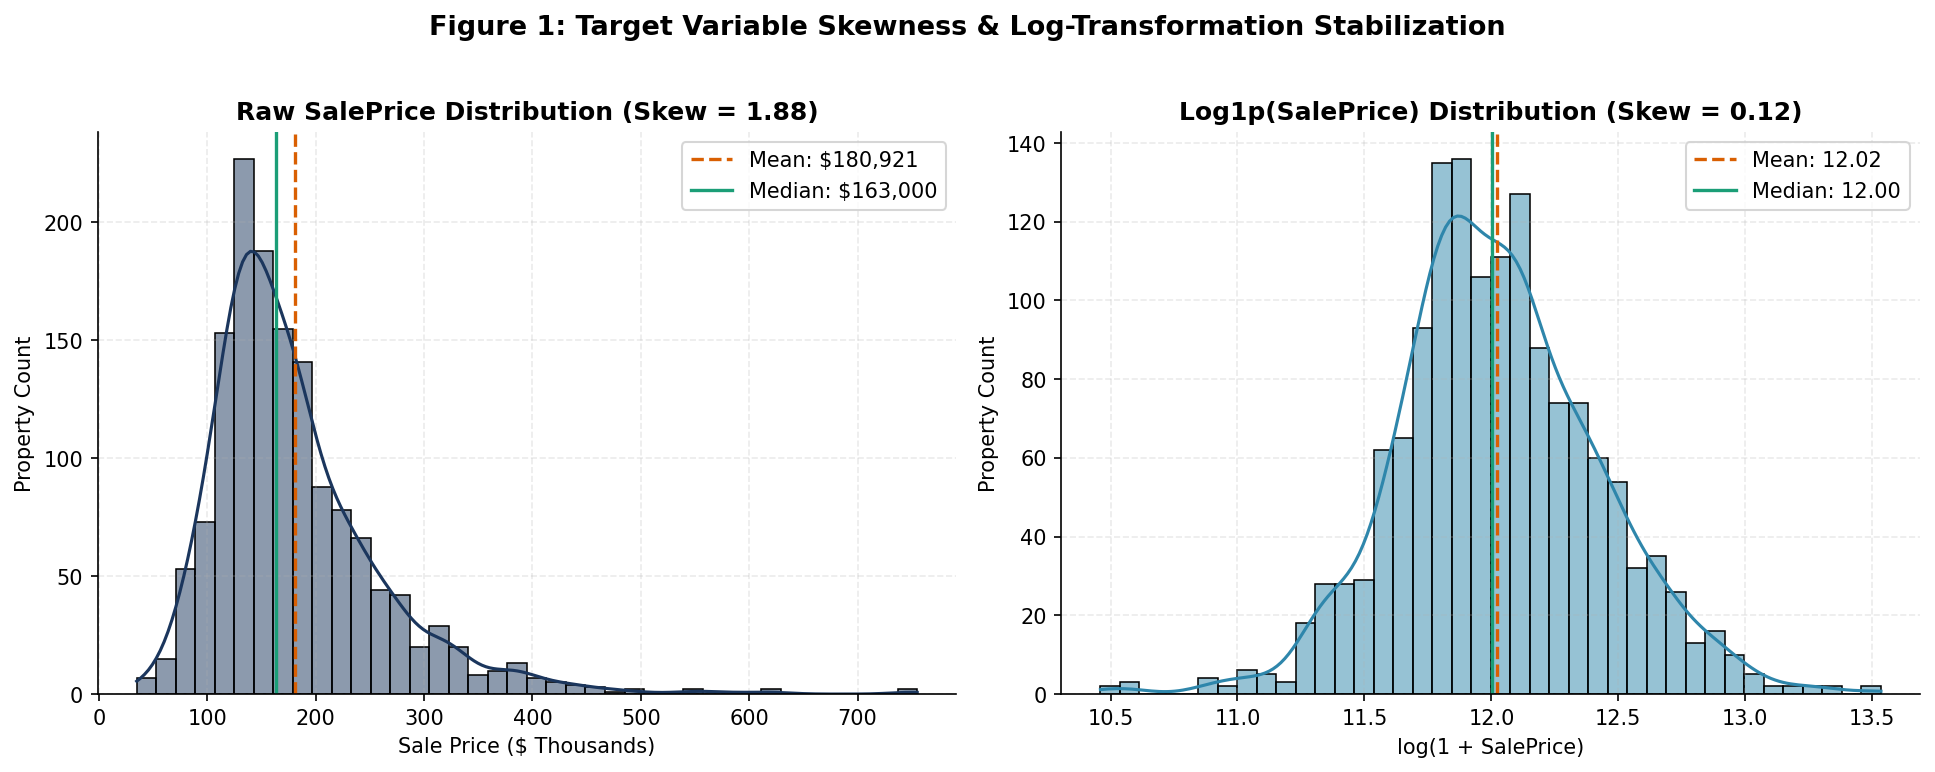

In [2]:
print('=== SalePrice Summary & Outlier Thresholds ===')
print(json.dumps(results['distributions']['sale_price_summary'], indent=2))

display(results['distributions']['distribution_table'])
print('\n=== Extreme Above-Grade Living Area Records (GrLivArea > 4,000 sq ft) ===')
display(pd.DataFrame(results['distributions']['grliv_extreme_records']))
display(Image(filename=f'{figures_dir}/fig1_target_distributions.png'))

## 2. Linear & Rank Correlations with SalePrice
We evaluate both Pearson ($r$) and Spearman ($\rho$) correlations across structural Kaggle features and Module 1 synthetic contextual features.

=== Top 15 Overall Correlates with SalePrice ===


,Feature,Pearson_r_SalePrice,Spearman_rho_SalePrice,Pearson_r_LogSalePrice,Abs_Pearson_r,p_value
0,OverallQual,0.7910,0.8098,0.8172,0.7910,2.185675e-313
1,GrLivArea,0.7086,0.7313,0.7009,0.7086,4.518034e-223
2,GarageCars,0.6404,0.6907,0.6806,0.6404,2.498644e-169
3,GarageArea,0.6234,0.6494,0.6509,0.6234,5.265038e-158
4,TotalBsmtSF,0.6136,0.6027,0.6121,0.6136,9.484229e-152
5,1stFlrSF,0.6059,0.5754,0.5970,0.6059,5.394711e-147
6,FullBath,0.5607,0.6360,0.5948,0.5607,1.236470e-121
7,TotRmsAbvGrd,0.5337,0.5326,0.5344,0.5337,2.772281e-108
8,PropertyAge,-0.5234,-0.6501,-0.5873,0.5234,1.856539e-103
9,YearBuilt,0.5229,0.6527,0.5866,0.5229,2.990229e-103



=== Synthetic Contextual Feature Correlations ===


,Feature,Pearson_r_SalePrice,Spearman_rho_SalePrice,Pearson_r_LogSalePrice,Abs_Pearson_r,p_value
0,amenity_composite_score,-0.4964,-0.5620,-0.5134,0.4964,1.173674e-91
1,distance_to_hospital_km,0.4741,0.5307,0.5146,0.4741,1.114241e-82
2,distance_to_school_km,0.4601,0.5394,0.4684,0.4601,2.317226e-77
3,distance_to_transit_km,0.4531,0.5047,0.4557,0.4531,8.139930e-75
4,renovation_cost_usd,0.3688,0.0734,0.3240,0.3688,2.868908e-48
5,days_on_market,-0.1355,-0.1429,-0.1527,0.1355,2.013045e-07
6,has_renovation,-0.0862,-0.1545,-0.1339,0.0862,9.720970e-04
7,mortgage_rate_pct,0.0293,0.0448,0.0401,0.0293,2.640215e-01
8,local_price_index,0.0273,0.0266,0.0376,0.0273,2.963295e-01
9,unemployment_rate_pct,-0.0245,-0.0343,-0.0379,0.0245,3.491768e-01


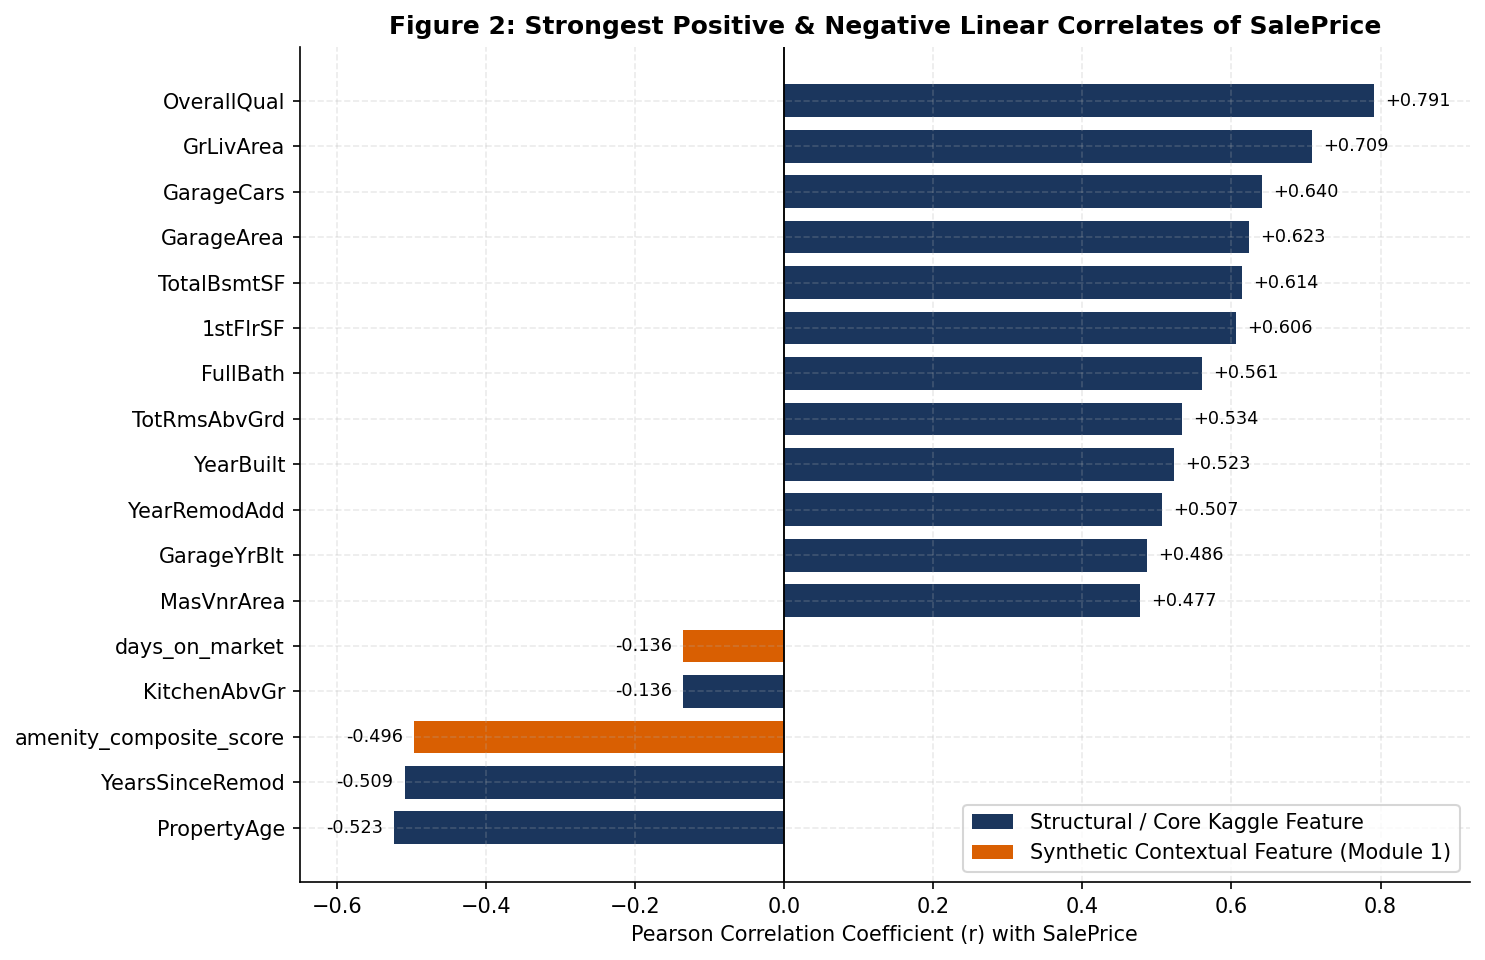

In [3]:
print('=== Top 15 Overall Correlates with SalePrice ===')
display(results['all_correlations'].head(15))

print('\n=== Synthetic Contextual Feature Correlations ===')
display(results['synthetic_correlations'])
display(Image(filename=f'{figures_dir}/fig2_feature_correlations.png'))

## 3. Stratified Price Comparisons: Location, Property Type & Age
Non-parametric Kruskal-Wallis $H$-tests verify statistically significant price stratification across neighborhoods, building types, and age cohorts.


--- NEIGHBORHOOD (Kruskal-Wallis H = 868.53, p = 6.70e-168) ---


,Neighborhood,Count,Mean,Median,Std,IQR
0,NridgHt,77,316270.623377,315000.0,96392.544954,120707.00
1,NoRidge,41,335295.317073,301500.0,121412.658640,76000.00
2,StoneBr,25,310499.000000,278000.0,112969.676640,163926.00
3,Timber,38,242247.447368,228475.0,64845.651549,99215.75
4,Somerst,86,225379.837209,225500.0,56177.555888,74944.50
5,Veenker,11,238772.727273,218000.0,72369.317959,97750.00
6,Crawfor,51,210624.725490,200624.0,68866.395472,79750.00
7,ClearCr,28,212565.428571,200250.0,50231.538993,58475.00
8,CollgCr,150,197965.773333,197200.0,51403.666438,72766.25
9,Blmngtn,17,194870.882353,191000.0,30393.229219,39490.00



--- BLDG_TYPE (Kruskal-Wallis H = 69.80, p = 2.50e-14) ---


,BldgType,Count,Mean,Median,Std,IQR
0,TwnhsE,114,181959.342105,172200.0,60626.108918,64187.5
1,1Fam,1220,185763.807377,167900.0,82648.502922,90525.0
2,Twnhs,43,135911.627907,137500.0,41013.222080,73000.0
3,Duplex,52,133541.076923,135980.0,27833.249197,26625.0
4,2fmCon,31,128432.258065,127500.0,35458.545158,35625.0



--- HOUSE_STYLE (Kruskal-Wallis H = 185.43, p = 1.39e-36) ---


,HouseStyle,Count,Mean,Median,Std,IQR
0,2.5Fin,8,220000.000000,194000.0,118211.976671,59500.0
1,2Story,445,210051.764045,190000.0,87339.213570,80500.0
2,SLvl,65,166703.384615,164500.0,38305.161339,33000.0
3,1Story,726,175985.477961,154750.0,77055.715011,82350.0
4,SFoyer,37,135074.486486,135960.0,30480.898192,20500.0
5,2.5Unf,11,157354.545455,133900.0,63934.128032,38500.0
6,1.5Fin,154,143116.740260,132000.0,54277.941119,44700.5
7,1.5Unf,14,110150.000000,111250.0,19036.473090,22325.0



--- AGE_COHORT (Kruskal-Wallis H = 664.00, p = 2.17e-142) ---


,AgeCohort,Count,Mean,Median,Std,IQR
0,0-10 yrs,434,238951.716590,219355.0,80632.972599,92368.75
1,11-25 yrs,158,226378.088608,201750.0,93738.413347,84375.00
2,26-50 yrs,429,153917.004662,145500.0,43061.253280,42000.00
3,51-75 yrs,238,136769.466387,129500.0,50134.807709,37750.00
4,75+ yrs,201,129804.154229,120500.0,51663.846707,48000.00



--- RENOVATION_TYPE (Kruskal-Wallis H = 329.59, p = 3.92e-71) ---


,renovation_type_clean,Count,Mean,Median,Std,IQR
0,Major_Structural,42,320398.476190,304400.0,94017.474382,71087.5
1,Kitchen_Bath,261,218259.061303,191000.0,94011.423314,108000.0
2,None,665,188409.378947,176000.0,72556.603621,85300.0
3,Cosmetic,492,139086.093496,135000.0,44508.557096,49625.0


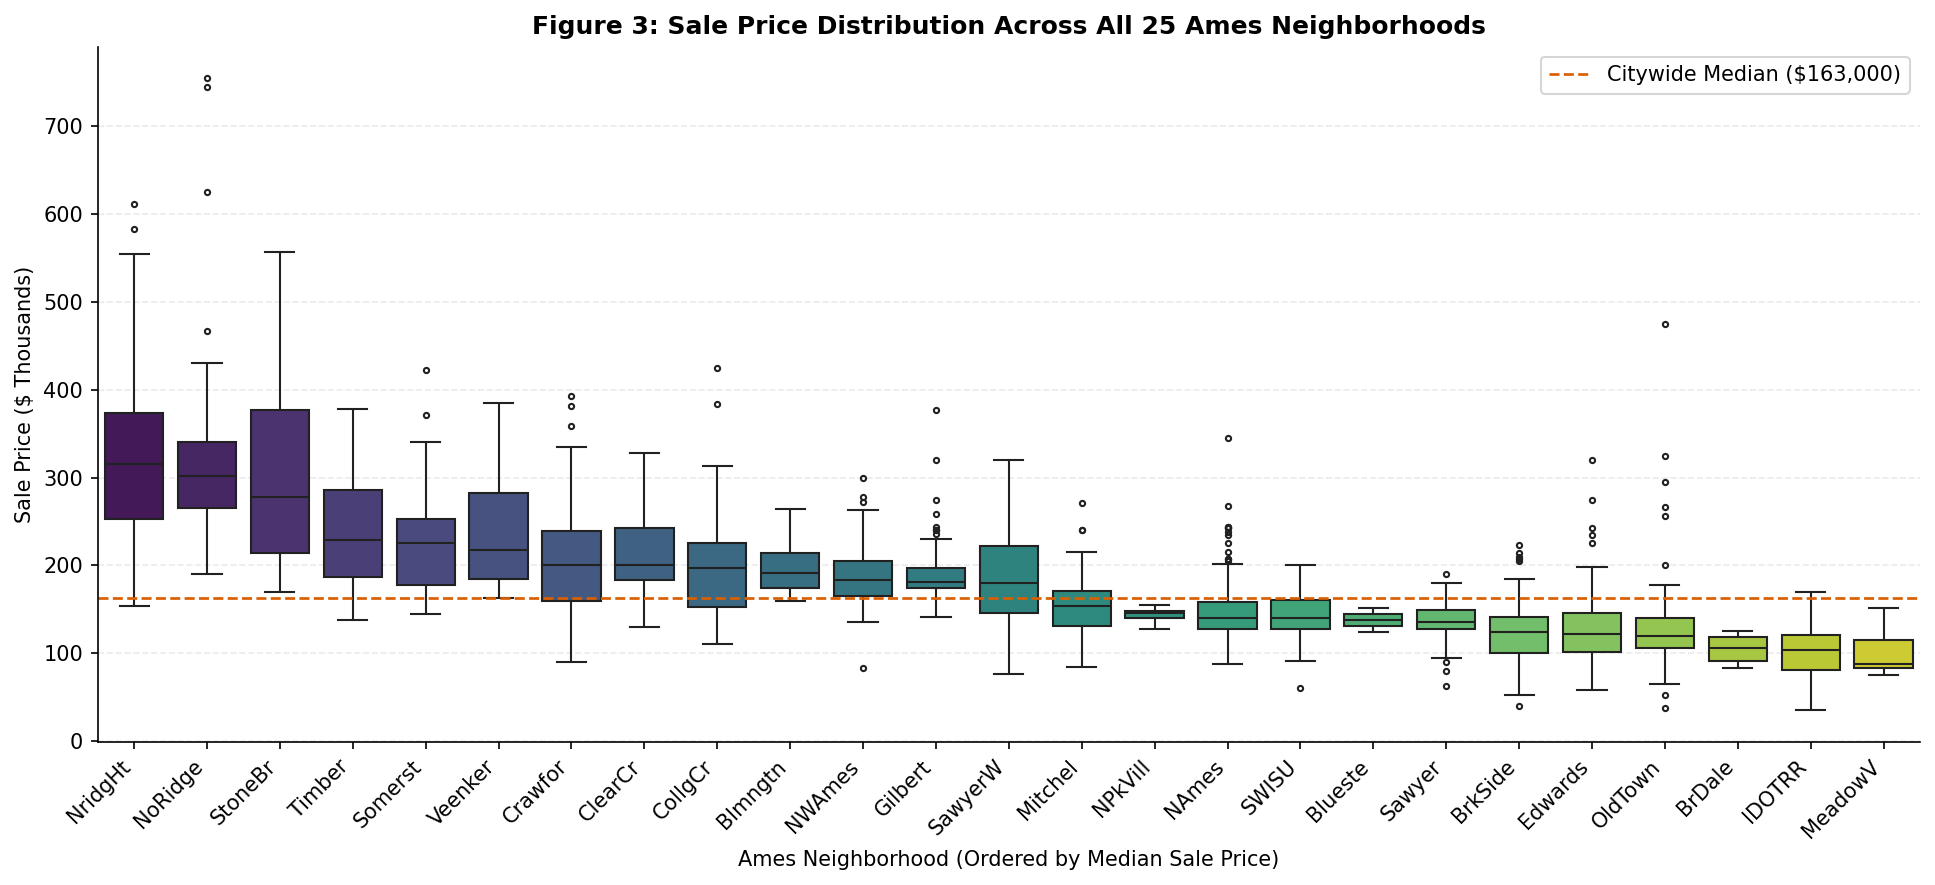

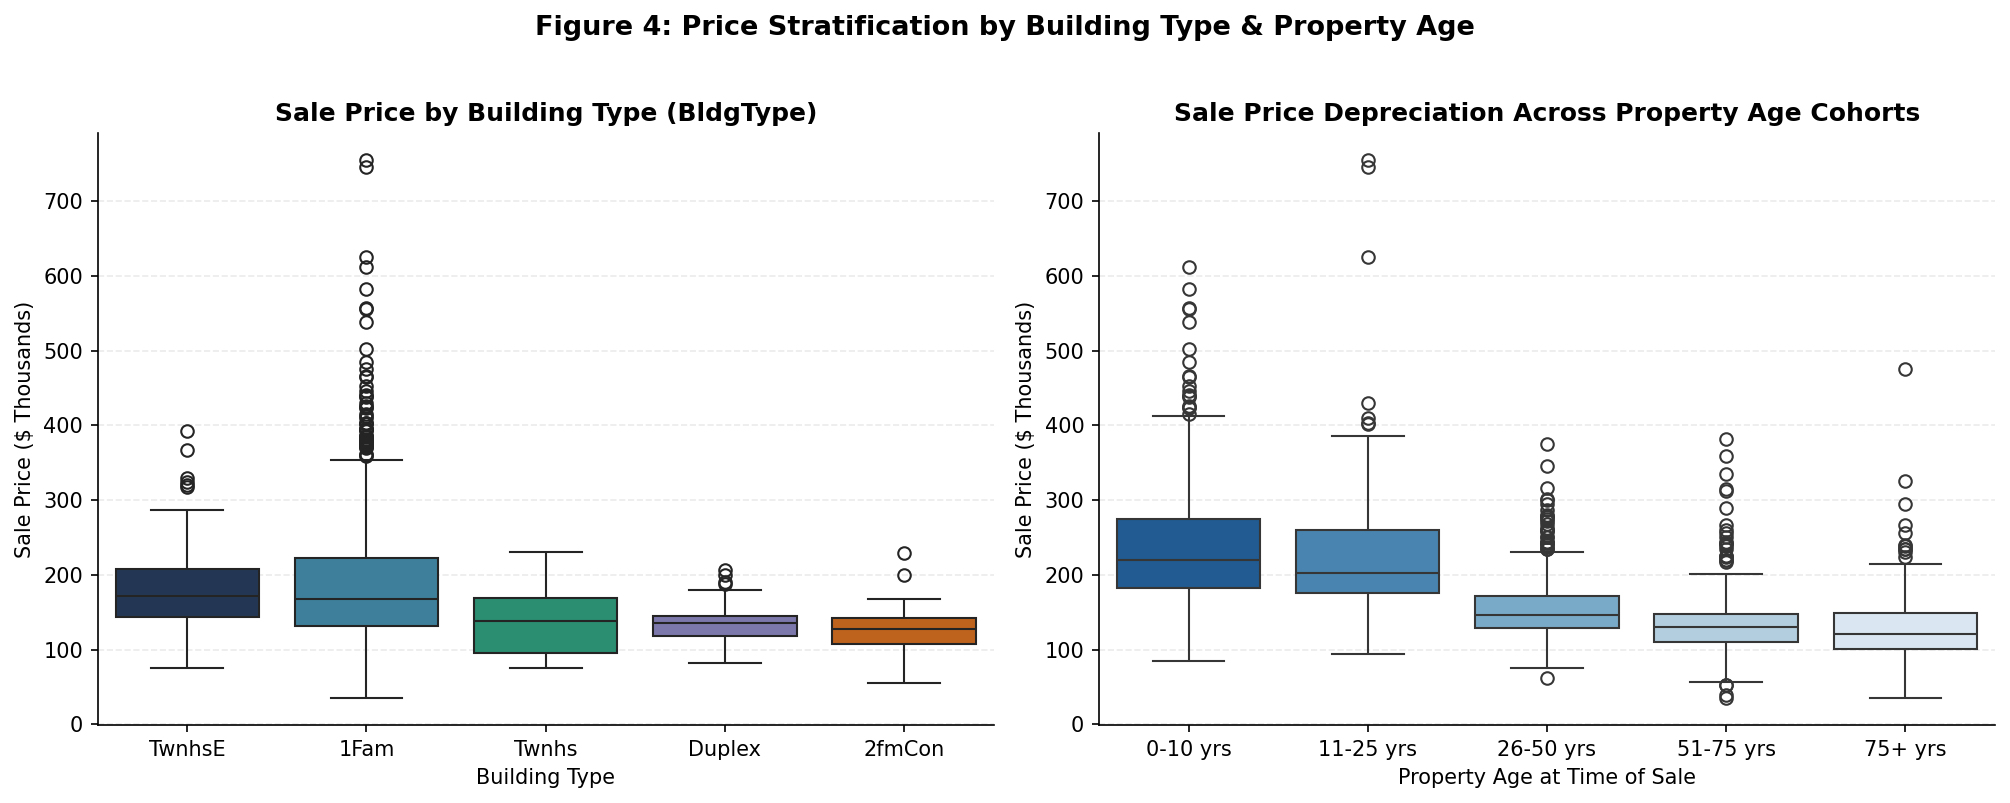

In [4]:
for group_key in ['neighborhood', 'bldg_type', 'house_style', 'age_cohort', 'renovation_type']:
    info = results['stratified_patterns'][group_key]
    print(f"\n--- {group_key.upper()} (Kruskal-Wallis H = {info['kruskal_stat']:.2f}, p = {info['kruskal_pvalue']:.2e}) ---")
    display(info['summary_table'])

display(Image(filename=f'{figures_dir}/fig3_price_by_neighborhood.png'))
display(Image(filename=f'{figures_dir}/fig4_price_by_type_and_age.png'))

## 4. Bivariate Relationships & Multicollinearity Diagnostics (VIF)
We inspect bivariate non-linearities and audit pairwise collinearity ($|r| \ge 0.70$) alongside intercept-adjusted Variance Inflation Factors (VIF).

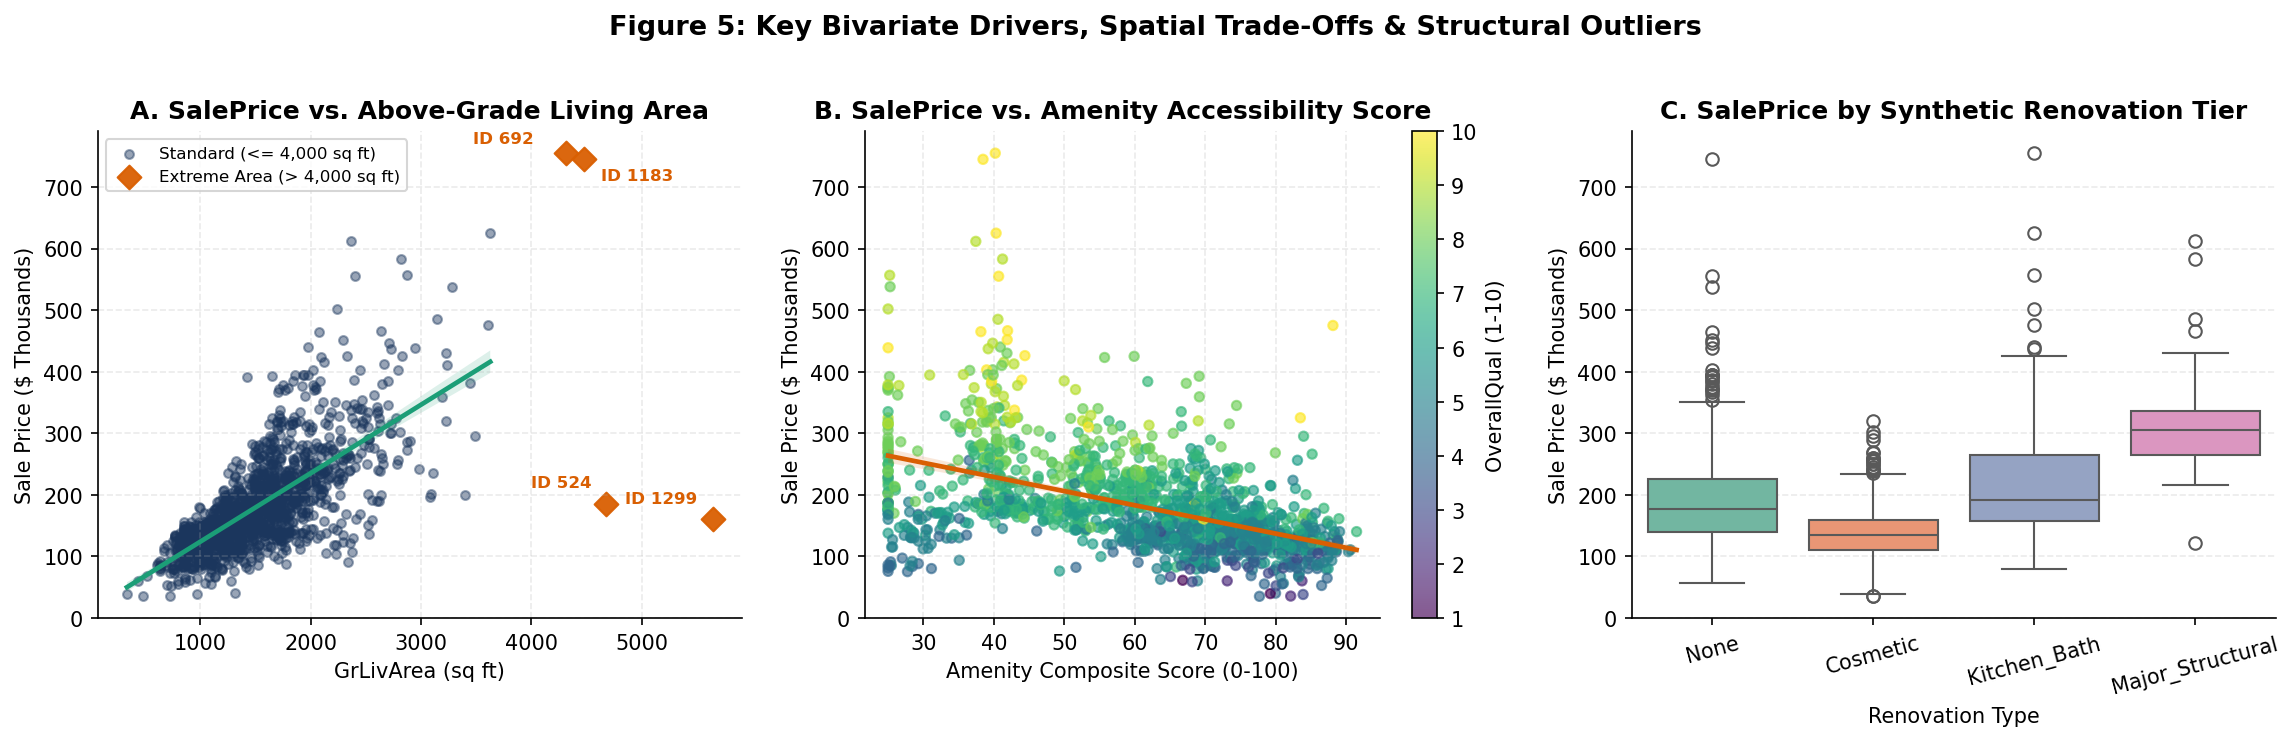

=== High Pairwise Collinearity Pairs (|r| >= 0.70) ===


,Feature_1,Feature_2,Abs_Pearson_r
0,mortgage_rate_pct,unemployment_rate_pct,0.9695
1,mortgage_rate_pct,local_price_index,0.9652
2,local_price_index,unemployment_rate_pct,0.9643
3,distance_to_school_km,amenity_composite_score,0.9513
4,distance_to_transit_km,amenity_composite_score,0.9388
5,YrSold,mortgage_rate_pct,0.9380
6,distance_to_hospital_km,amenity_composite_score,0.9353
7,YrSold,local_price_index,0.9126
8,distance_to_school_km,distance_to_transit_km,0.9046
9,YrSold,unemployment_rate_pct,0.8982



=== Intercept-Adjusted Variance Inflation Factor (VIF) Audit ===


,Feature,VIF,Severity
0,GrLivArea,181.43,Severe (VIF >= 10)
1,2ndFlrSF,130.38,Severe (VIF >= 10)
2,1stFlrSF,104.06,Severe (VIF >= 10)
3,amenity_composite_score,62.84,Severe (VIF >= 10)
4,mortgage_rate_pct,21.98,Severe (VIF >= 10)
5,unemployment_rate_pct,21.13,Severe (VIF >= 10)
6,local_price_index,18.86,Severe (VIF >= 10)
7,distance_to_hospital_km,18.46,Severe (VIF >= 10)
8,distance_to_transit_km,16.45,Severe (VIF >= 10)
9,distance_to_school_km,11.79,Severe (VIF >= 10)


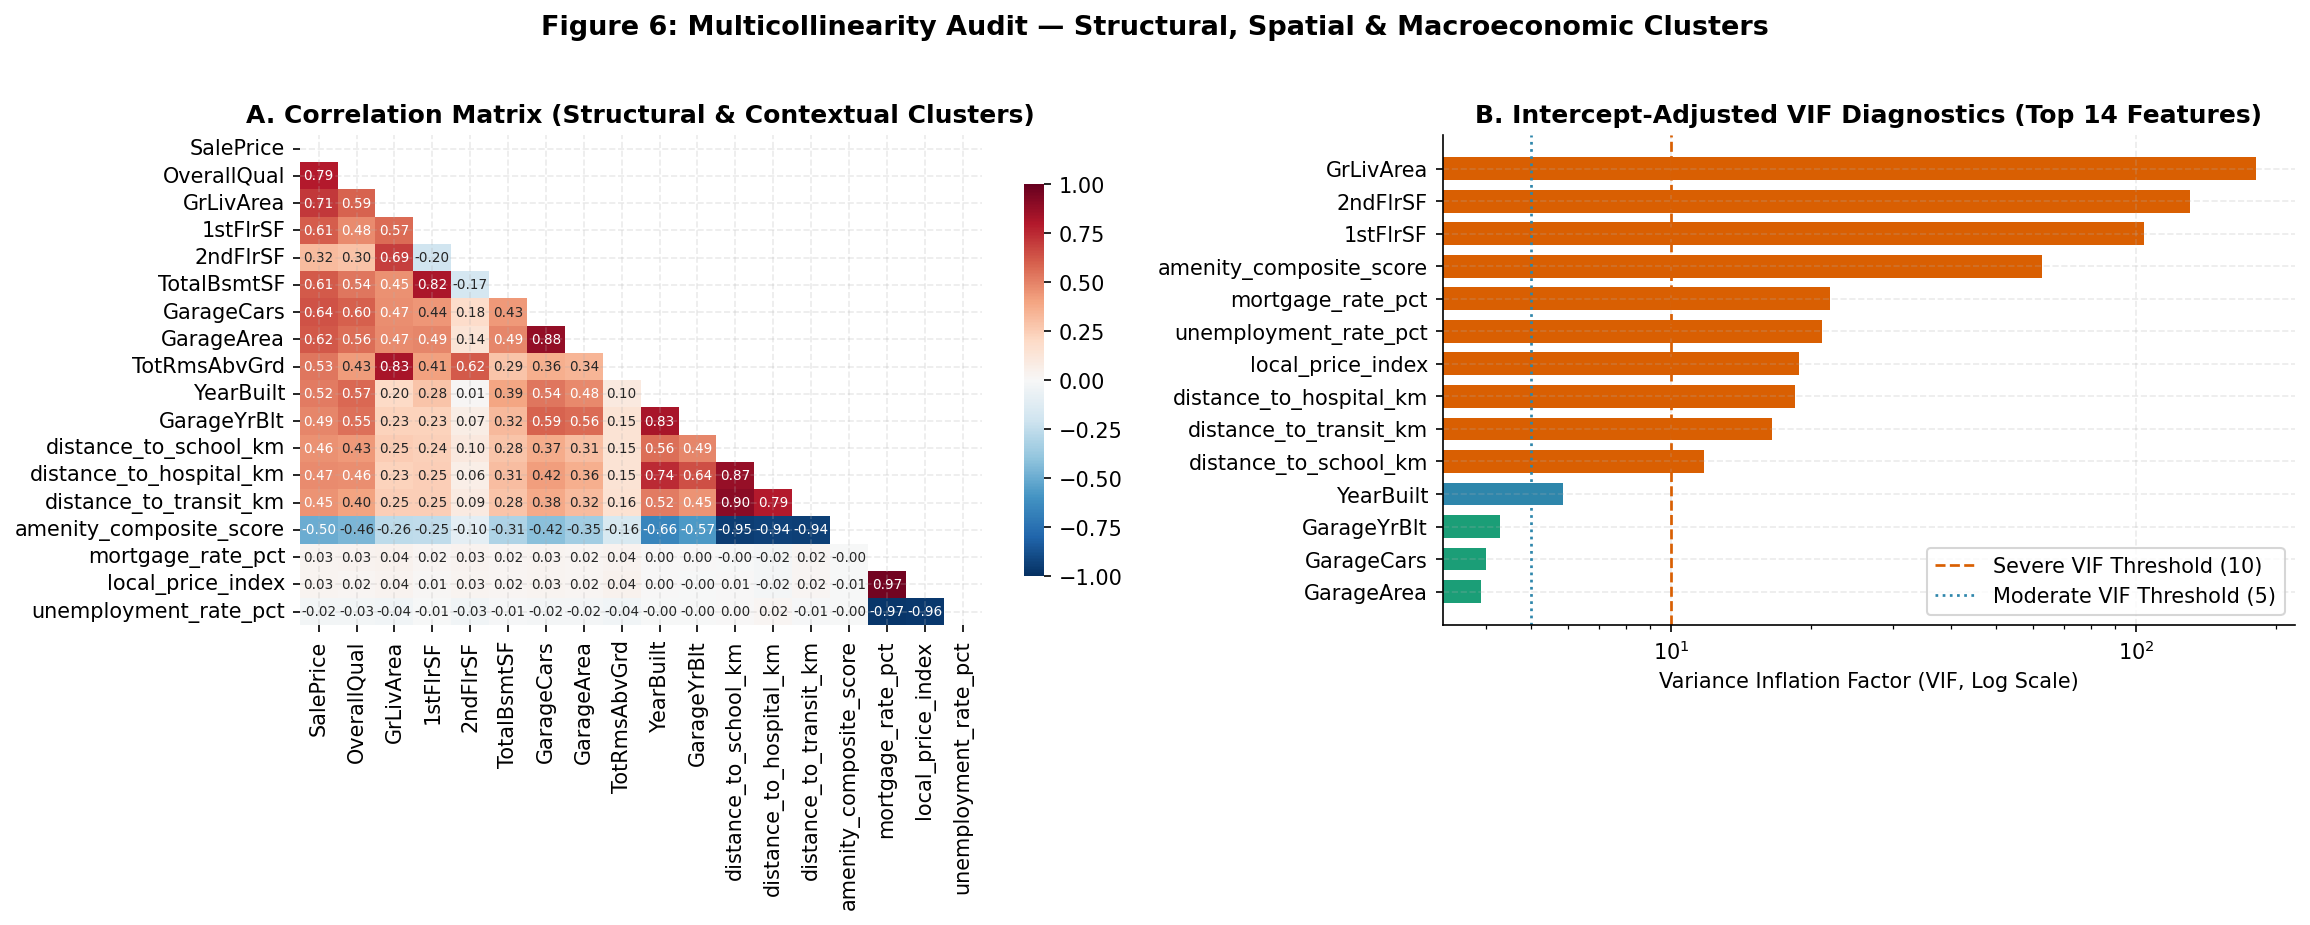

In [5]:
display(Image(filename=f'{figures_dir}/fig5_bivariate_relationships.png'))

print('=== High Pairwise Collinearity Pairs (|r| >= 0.70) ===')
display(results['high_corr_pairs'])

print('\n=== Intercept-Adjusted Variance Inflation Factor (VIF) Audit ===')
display(results['vif_table'])
display(Image(filename=f'{figures_dir}/fig6_multicollinearity_vif.png'))